# Progetto 5G Networks (Gruppo 2)
## Sorgente da trasmettere

In [2]:
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PERCORSO = Path("dataset") / "entropy.txt"
if not PERCORSO.exists():
    PERCORSO = Path("notebooks") / "dataset" / "entropy.txt"

text = PERCORSO.read_text(encoding="utf-8")
dati = text.encode("utf-8")

print("LUNGHEZZA TESTO:\t", len(text), "caratteri")
print("DIMENSIONE IN BIT:\t", len(dati) * 8, "bit (byte UTF-8 x 8)")
print(text[:500])

LUNGHEZZA TESTO:	 1842 caratteri
DIMENSIONE IN BIT:	 14736 bit (byte UTF-8 x 8)
A Mathematical Theory of Communication
By C. E. SHANNON
INTRODUCTION
THE recent development of various methods of modulation such as PCM and PPM which exchange bandwidth for signal-to-noise ratio has intensified the interest in a general theory of communication. A basis for such a theory is contained in the important papers of Nyquist and Hartley on this subject. In the present paper we will extend the theory to include a number of new factors, in particular the effect of noise in the channel, a


## Codifica di sorgente: LZ78

L'header (numero di coppie, 32 bit) viene ripetuto `REP` volte e decodificato a maggioranza, così un singolo bit errato non lo corrompe. Il decoder si ferma quando i bit finiscono.

In [3]:
REP = 5  # ripetizioni dell'header

def lz78_encode(data: bytes) -> np.ndarray:
    dizionario, coppie, corrente = {}, [], b""
    for b in data:
        c = bytes([b])
        if corrente + c in dizionario:
            corrente += c
        else:
            coppie.append((dizionario.get(corrente, 0), b))
            dizionario[corrente + c] = len(dizionario) + 1
            corrente = b""
    if corrente:
        coppie.append((dizionario.get(corrente[:-1], 0), corrente[-1]))
    return np.array(coppie, dtype=np.int64)


def lz78_decode(coppie: np.ndarray) -> bytes:
    dizionario = [b""]
    out = bytearray()
    for indice, simbolo in coppie:
        prefisso = dizionario[indice] if indice < len(dizionario) else b""  # indice corrotto -> fallback
        s = prefisso + bytes([int(simbolo)])
        out += s
        dizionario.append(s)
    return bytes(out)


def _int_to_bits(x: int, w: int) -> np.ndarray:
    return ((x >> np.arange(w - 1, -1, -1)) & 1).astype(np.int8)


def _bits_to_int(b: np.ndarray) -> int:
    return int(np.dot(b.astype(np.int64), 1 << np.arange(len(b) - 1, -1, -1, dtype=np.int64))) if len(b) else 0


def coppie_to_bits(coppie: np.ndarray) -> np.ndarray:
    n = len(coppie)
    pezzi = [np.tile(_int_to_bits(n, 32), REP)]
    for i, (indice, simbolo) in enumerate(coppie):
        w = i.bit_length()
        if w:
            pezzi.append(_int_to_bits(int(indice), w))
        pezzi.append(_int_to_bits(int(simbolo), 8))
    return np.concatenate(pezzi).astype(np.int8)


def bits_to_coppie(bits: np.ndarray) -> np.ndarray:
    hdr = bits[:32 * REP].reshape(REP, 32)
    n = _bits_to_int((hdr.sum(axis=0) * 2 > REP).astype(np.int64))  # voto a maggioranza
    pos, coppie = 32 * REP, []
    for i in range(n):
        w = i.bit_length()
        if pos + w + 8 > len(bits):      # bit finiti (stream troncato / n errato)
            break
        indice = _bits_to_int(bits[pos:pos + w]); pos += w
        simbolo = _bits_to_int(bits[pos:pos + 8]); pos += 8
        coppie.append((indice, simbolo))
    return np.array(coppie, dtype=np.int64).reshape(-1, 2)

In [4]:
compresso = lz78_encode(dati)
bits = coppie_to_bits(compresso)
print(len(compresso), "coppie ->", len(bits), "bit")

# Verifica canale ideale
assert lz78_decode(bits_to_coppie(bits)).decode("utf-8") == text
print("Round trip senza canale: OK")

644 coppie -> 10729 bit
Round trip senza canale: OK


## Canale: 2-PAM + AWGN + fading di Rayleigh

In [5]:
def sendPAM(SNR_dB, sorgente, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    simboli = 2 * sorgente.astype(int) - 1
    SNR = 10 ** (SNR_dB / 10)
    sigma = np.sqrt(1 / (2 * SNR))
    rumore = sigma * rng.standard_normal(len(sorgente))
    a = np.sqrt(rng.exponential(1.0, len(sorgente)))
    return ((a * simboli + rumore) > 0).astype(np.int8)


def ber_teorica(SNR_dB):
    g = 10 ** (np.asarray(SNR_dB) / 10)
    return 0.5 * (1 - np.sqrt(g / (1 + g)))

## Ricezione e statistiche

In [6]:
from rapidfuzz.distance import Levenshtein

def trasmetti(SNR_dB, seed=None):
    rng = np.random.default_rng(seed)
    rx = sendPAM(SNR_dB, bits, rng)
    ricevuto = lz78_decode(bits_to_coppie(rx)).decode("utf-8", errors="replace")
    errori_bit = int(np.sum(rx != bits))
    cer = Levenshtein.distance(text, ricevuto) / len(text)
    return rx, ricevuto, errori_bit, cer

rx, ricevuto, errori_bit, cer = trasmetti(20, seed=1)

bit_orig, bit_comp = len(dati) * 8, len(bits)
print("=== STATISTICHE (SNR = 20 dB) ===")
print(f"BER:  {errori_bit/len(bits):.3e} ({errori_bit} errati su {len(bits)}) | teorica {ber_teorica(20):.3e}")
print(f"CER (Levenshtein): {cer:.2%}")
print(f"Testo identico: {text == ricevuto}")
print(f"Compressione: {bit_orig/bit_comp:.2f}:1 | spazio risparmiato {100*(1-bit_comp/bit_orig):.2f}%")
print(ricevuto[:500])

=== STATISTICHE (SNR = 20 dB) ===
BER:  2.423e-03 (26 errati su 10729) | teorica 2.481e-03
CER (Levenshtein): 7.49%
Testo identico: False
Compressione: 1.37:1 | spazio risparmiato 27.19%
A Mauhematical Theory of Communication
By C* E* SHANNON
�NTRODUCP�ON
THE recenu development of various methods of modulation such o�s PCM o�nd PPM which exchange randwiduh for signal-uo-noise ratio haPintensified the inuerest in a general uheory of communicaion. A basis for such a uheory is contained kn the important papers of Nyquist and Hartley on this subject* In the present paper we will exuend the theory uo include o� numb Hof new factors, in paricular uhe effect of nheise in uhe channel, a


## Sweep SNR: BER e CER (media su più realizzazioni)

SNR  0 dB | BER 1.44e-01 | CER 99.29%
SNR  4 dB | BER 7.91e-02 | CER 83.25%
SNR  8 dB | BER 3.46e-02 | CER 49.50%
SNR 12 dB | BER 1.39e-02 | CER 23.80%
SNR 16 dB | BER 6.13e-03 | CER 9.91%
SNR 20 dB | BER 2.13e-03 | CER 6.36%
SNR 24 dB | BER 8.39e-04 | CER 2.27%
SNR 28 dB | BER 3.17e-04 | CER 0.38%
SNR 32 dB | BER 1.30e-04 | CER 0.33%
SNR 36 dB | BER 9.32e-05 | CER 0.13%
SNR 40 dB | BER 1.86e-05 | CER 0.01%


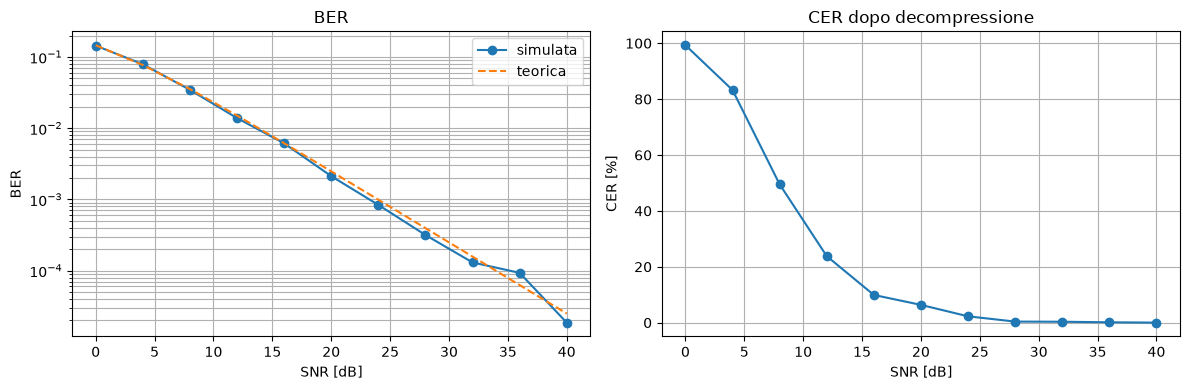

In [7]:
snr_range = np.arange(0, 41, 4)
N_RUN = 5
ber_sim, cer_sim = [], []
for snr in snr_range:
    b, c_ = [], []
    for k in range(N_RUN):
        _, _, eb, cer_k = trasmetti(snr, seed=1000 * int(snr) + k)
        b.append(eb / len(bits)); c_.append(cer_k)
    ber_sim.append(np.mean(b)); cer_sim.append(np.mean(c_))
    print(f"SNR {snr:2d} dB | BER {ber_sim[-1]:.2e} | CER {cer_sim[-1]:.2%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(snr_range, np.maximum(ber_sim, 1e-9), "o-", label="simulata")
ax[0].semilogy(snr_range, ber_teorica(snr_range), "--", label="teorica")
ax[0].set(xlabel="SNR [dB]", ylabel="BER", title="BER"); ax[0].legend(); ax[0].grid(True, which="both")
ax[1].plot(snr_range, 100 * np.array(cer_sim), "o-")
ax[1].set(xlabel="SNR [dB]", ylabel="CER [%]", title="CER dopo decompressione"); ax[1].grid(True)
plt.tight_layout(); plt.show()